6. PCA + Classification 

In [1]:
# ===========================================
#  Imports & Load MNIST Digits (8x8)
# ===========================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# For classification
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Replace with your email username for plots
username = "kuluri.sarvani"


# Load digits dataset
digits = load_digits()
X = digits.data.astype(np.float64)   # 8x8 images flattened to 64 features
y = digits.target

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)


Dataset shape: (1797, 64)
Labels shape: (1797,)


## 6.1 Data Loading and Preparation 

In [2]:
# ===========================================
#  Split Dataset into Train and Test
# ===========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)


Training set shape: (1437, 64)
Testing set shape: (360, 64)


In [3]:
# ===========================================
# 🔹 Feature Scaling
# ===========================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data mean (approx.):", np.mean(X_train_scaled, axis=0)[:5])
print("Scaled training data std (approx.):", np.std(X_train_scaled, axis=0)[:5])


Scaled training data mean (approx.): [ 0.00000000e+00 -2.60519975e-16 -4.01364552e-17  1.51429167e-16
  2.99111235e-16]
Scaled training data std (approx.): [0. 1. 1. 1. 1.]


In [4]:
# ===========================================
#  PCA Class (Custom Implementation)
# ===========================================
class PCA_Custom:
    """
    Principal Component Analysis (PCA) implementation from scratch.
    """

    def __init__(self, n_components):
        """
        Initialize PCA class.

        Parameters:
        -----------
        n_components : int
            Number of principal components to reduce data to.
        """
        self.n_components = n_components
        self.components_ = None
        self.mean_ = None
        self.explained_variance_ = None

    def fit(self, X):
        """
        Compute principal components of the dataset.

        Parameters:
        -----------
        X : np.ndarray
            Input dataset of shape (n_samples, n_features)
        """
        # Center the data
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_

        # Compute covariance matrix
        cov_matrix = np.cov(X_centered, rowvar=False)

        # Eigen decomposition
        eigen_values, eigen_vectors = np.linalg.eigh(cov_matrix)

        # Sort eigenvectors by decreasing eigenvalues
        sorted_idx = np.argsort(eigen_values)[::-1]
        self.explained_variance_ = eigen_values[sorted_idx][:self.n_components]
        self.components_ = eigen_vectors[:, sorted_idx][:, :self.n_components]

    def transform(self, X):
        """
        Transform data to lower-dimensional space using principal components.

        Parameters:
        -----------
        X : np.ndarray
            Input dataset of shape (n_samples, n_features)

        Returns:
        --------
        X_transformed : np.ndarray
            Dataset projected onto principal components.
        """
        X_centered = X - self.mean_
        return np.dot(X_centered, self.components_)

    def checkPCA(self, X):
        """
        Check if PCA reduces dimensions correctly.

        Parameters:
        -----------
        X : np.ndarray
            Input dataset

        Returns:
        --------
        bool : True if transformed data has correct shape, False otherwise
        """
        X_transformed = self.transform(X)
        return X_transformed.shape[1] == self.n_components


In [5]:
# ===========================================
#  Apply PCA to Training Data
# ===========================================
n_components = 20  # Example: reduce to 20 dimensions
pca = PCA_Custom(n_components=n_components)
pca.fit(X_train_scaled)

X_train_pca = pca.transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original training shape:", X_train_scaled.shape)
print("Transformed training shape:", X_train_pca.shape)


Original training shape: (1437, 64)
Transformed training shape: (1437, 20)


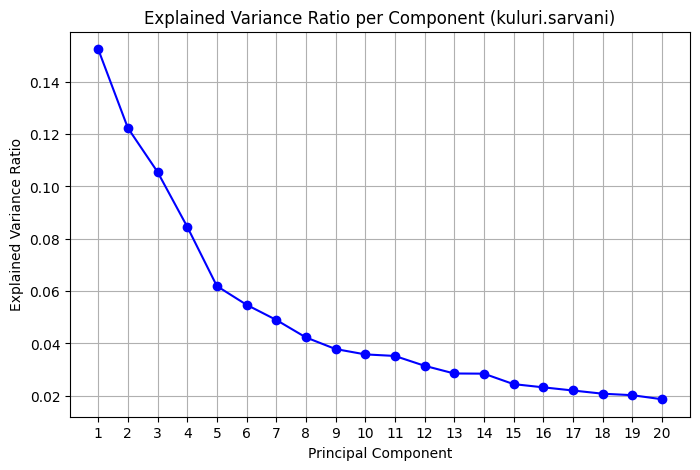

In [6]:
# ===========================================
# Explained Variance Ratio Plot
# ===========================================
explained_variance_ratio = pca.explained_variance_ / np.sum(pca.explained_variance_)

plt.figure(figsize=(8,5))
plt.plot(range(1, n_components+1), explained_variance_ratio, marker='o', linestyle='-', color='b')
plt.title(f"Explained Variance Ratio per Component ({username})")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.xticks(range(1, n_components+1))
plt.grid(True)
plt.show()


## 6.2 Dimensionality Reduction with PCA 

In [7]:
# ===========================================
# Dimensionality Reduction for Multiple Components
# ===========================================

# List of target dimensions
n_components_list = [2, 5, 10, 20, 30, 40, 50, 64]

# Dictionaries to store transformed datasets
X_train_pca_dict = {}
X_test_pca_dict = {}

for n_comp in n_components_list:
    # Initialize PCA
    pca = PCA_Custom(n_components=n_comp)
    pca.fit(X_train_scaled)
    
    # Transform training and testing data
    X_train_pca_dict[n_comp] = pca.transform(X_train_scaled)
    X_test_pca_dict[n_comp] = pca.transform(X_test_scaled)
    
    print(f"PCA applied for {n_comp} components -> Training shape: {X_train_pca_dict[n_comp].shape}, Testing shape: {X_test_pca_dict[n_comp].shape}")


PCA applied for 2 components -> Training shape: (1437, 2), Testing shape: (360, 2)
PCA applied for 5 components -> Training shape: (1437, 5), Testing shape: (360, 5)
PCA applied for 10 components -> Training shape: (1437, 10), Testing shape: (360, 10)
PCA applied for 20 components -> Training shape: (1437, 20), Testing shape: (360, 20)
PCA applied for 30 components -> Training shape: (1437, 30), Testing shape: (360, 30)
PCA applied for 40 components -> Training shape: (1437, 40), Testing shape: (360, 40)
PCA applied for 50 components -> Training shape: (1437, 50), Testing shape: (360, 50)
PCA applied for 64 components -> Training shape: (1437, 64), Testing shape: (360, 64)


## 6.3 Classification with KNN 

In [8]:
# ===========================================
#  KNN Classification on PCA-Reduced Data
# ===========================================

from sklearn.metrics import accuracy_score

# List of k values for KNN
k_values = [5, 25, 50, 100]

# Dictionary to store accuracies
accuracy_results = {}

for n_comp in n_components_list:
    accuracy_results[n_comp] = {}
    X_train_pca = X_train_pca_dict[n_comp]
    X_test_pca = X_test_pca_dict[n_comp]
    
    for k in k_values:
        # Initialize KNN
        knn = KNeighborsClassifier(n_neighbors=k)
        
        # Train on PCA-reduced training data
        knn.fit(X_train_pca, y_train)
        
        # Predict on PCA-reduced test data
        y_pred = knn.predict(X_test_pca)
        
        # Compute accuracy
        acc = accuracy_score(y_test, y_pred)
        accuracy_results[n_comp][k] = acc
        
        print(f"PCA {n_comp} components, k={k} -> Test Accuracy: {acc:.4f}")


PCA 2 components, k=5 -> Test Accuracy: 0.5222
PCA 2 components, k=25 -> Test Accuracy: 0.5361
PCA 2 components, k=50 -> Test Accuracy: 0.5194
PCA 2 components, k=100 -> Test Accuracy: 0.5250
PCA 5 components, k=5 -> Test Accuracy: 0.8306
PCA 5 components, k=25 -> Test Accuracy: 0.8139
PCA 5 components, k=50 -> Test Accuracy: 0.7889
PCA 5 components, k=100 -> Test Accuracy: 0.7611
PCA 10 components, k=5 -> Test Accuracy: 0.9444
PCA 10 components, k=25 -> Test Accuracy: 0.9083
PCA 10 components, k=50 -> Test Accuracy: 0.8611
PCA 10 components, k=100 -> Test Accuracy: 0.8472
PCA 20 components, k=5 -> Test Accuracy: 0.9528
PCA 20 components, k=25 -> Test Accuracy: 0.9333
PCA 20 components, k=50 -> Test Accuracy: 0.8972
PCA 20 components, k=100 -> Test Accuracy: 0.8833
PCA 30 components, k=5 -> Test Accuracy: 0.9694
PCA 30 components, k=25 -> Test Accuracy: 0.9222
PCA 30 components, k=50 -> Test Accuracy: 0.9000
PCA 30 components, k=100 -> Test Accuracy: 0.8833
PCA 40 components, k=5 -> Te

## 6.4 Visualization and Analysis 

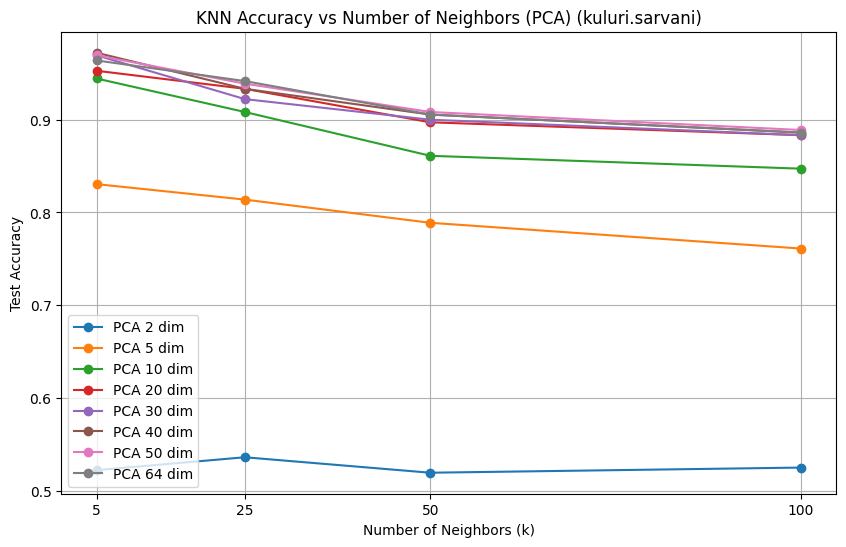

In [9]:
# ===========================================
#  Visualize KNN Accuracy
# ===========================================
plt.figure(figsize=(10,6))

for n_comp in n_components_list:
    accuracies = [accuracy_results[n_comp][k] for k in k_values]
    plt.plot(k_values, accuracies, marker='o', linestyle='-', label=f"PCA {n_comp} dim")

plt.title(f"KNN Accuracy vs Number of Neighbors (PCA) ({username})")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Test Accuracy")
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()


## 6.3 Classification with KNN 

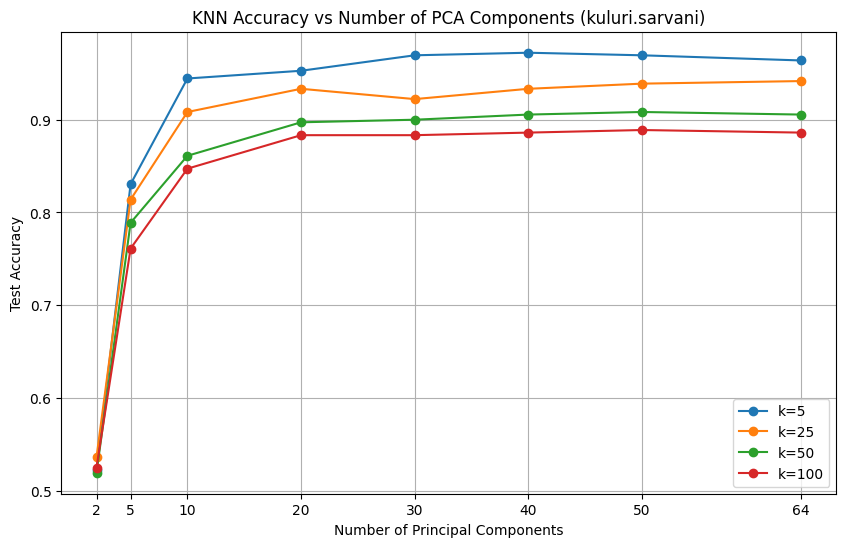

In [10]:
# ===========================================
# Combined Visualization: PCA Dimensions vs KNN Accuracy
# ===========================================

plt.figure(figsize=(10,6))

# Plot accuracy for each k value across all PCA dimensions
for k in k_values:
    accuracies_for_k = [accuracy_results[n_comp][k] for n_comp in n_components_list]
    plt.plot(n_components_list, accuracies_for_k, marker='o', linestyle='-', label=f"k={k}")

plt.title(f"KNN Accuracy vs Number of PCA Components ({username})")
plt.xlabel("Number of Principal Components")
plt.ylabel("Test Accuracy")
plt.xticks(n_components_list)
plt.legend()
plt.grid(True)
plt.show()
